In [211]:
from config import *
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from scipy.spatial import cKDTree

## Load in Sample Data

In [212]:
parent = Table.read('out/parent.fits', unit_parse_strict = 'silent')

z = np.asarray(parent['Z'])
logM = np.asarray(parent['logmstar'])

## Calculate Positions and Distances

The RA and DEC converted to 3D cartesian coordinates on a unit sphere are
$$
\begin{align*}
    x &= \cos(\text{DEC}) \cos(\text{RA}) \\
    y &= \cos(\text{DEC}) \sin(\text{RA}) \\
    z &= \sin(\text{DEC})
\end{align*}
$$

In [213]:
# Calculate the angular diameter distance for each galaxy in the sample
dA = COSMO.angular_diameter_distance(z).to_value(u.kpc)

# Convert RA and DEC from degrees to radians
RA, DEC = np.radians(parent['RA']), np.radians(parent['DEC'])

# Convert spherical coordinates (RA, DEC) to Cartesian coordinates (x, y, z)
cx = np.cos(DEC) * np.cos(RA)
cy = np.cos(DEC) * np.sin(RA)
cz = np.sin(DEC)

# Construct a 3D grid of the galaxy positions in Cartesian coordinates
grid = np.column_stack((cx, cy, cz))

## Find Nearest Neighbours Using a KD-Tree

In [214]:
# Construct a KD-tree for efficient nearest neighbor search
tree = cKDTree(grid)

# Identify the indices of the primary galaxies in the sample
primary = np.where(parent['in_sample'])[0]

# Calculate the maximum angular separation corresponding to the projected separation limit
theta_max = RP_MAX / dA[primary]

# Convert the agular seperation limit to a chord length in 3D Cartesian coordinates
chord_max = 2 * np.sin(theta_max / 2)

# Find all neighbors within the chord length for each primary galaxy
neighbors = tree.query_ball_point(grid[primary], r = chord_max)

## Construct Array of Candidate Pairs

In [215]:
# The number of neighbors for each primary galaxy
counts = np.array([len(n) for n in neighbors])

# Create arrays of primary and neighbor indices for all pairs
i = np.repeat(primary, counts)

# Concatenate the list of neighbor indices into a single array
j = np.concatenate([np.asarray(n, dtype = int) for n in neighbors])

# Remove self-matches (a galaxy being its own neighbor) from the list of pairs
self_match = i == j
i, j = i[~self_match], j[~self_match]

## Calculate Seperations for Each Candidate Pair

The projected physical seperation between each pair is
$$
r_p = \theta \times d_A(z)
$$
where $d_A(x)$ is the angular diameter distance at the primary's redshift and $\theta$ is the angular seperation in radians.

In [216]:
# Calculate the angular separation between each pair of galaxies
chord = np.linalg.norm(grid[i] - grid[j], axis = 1)

# Convert the chord length to an angular separation in radians
theta = 2 * np.arcsin(chord / 2)

# Projected physical separation in kpc for each pair of galaxies
rp = theta * dA[i]

The velocity seperation between each pair is
$$
\Delta v = \frac{c |z_1 - z_2|}{1 + \bar z}
$$
where $\bar z$ is the average redshift between the pair.

In [217]:
# Average redshift of each pair of galaxies
zbar = 0.5 * (z[i] + z[j])

# Calculate the line-of-sight velocity difference for each pair of galaxies
dv = C_KMS * np.abs(z[i] - z[j]) / (1 + zbar)

The mass ratio of each pair is
$$
\mu = \frac{M_2}{M_1}
$$
where $M_2$ stellar mass of the less massive galaxy and $M_1$ is the stellar mass of the more massive galaxy.

In [218]:
# Calculate the stellar mass ratio for each pair of galaxies
logM1, logM2 = logM[i], logM[j]
mu = 10 ** - np.abs(logM2 - logM1)

## Apply the Pair Selection Criteria

In [219]:
# Determine which pairs of galaxies meet the selection criteria
qualifies = (rp <= RP_MAX) & (rp >= RP_MIN) & (dv <= DV_MAX) & (mu >= MU_MIN)
i_final, j_final = i[qualifies], j[qualifies]
rp_final, dv_final, mu_final = rp[qualifies], dv[qualifies], mu[qualifies]

# Sort the final pairs of galaxies by primary index and then by projected physical separation
order = np.lexsort((rp_final, i_final))
i_final, j_final = i_final[order], j_final[order]
rp_final, dv_final, mu_final = rp_final[order], dv_final[order], mu_final[order]

# Keep only the first companion for each primary galaxy (the closest qualifying companion)
closest = np.concatenate(([True], i_final[1:] != i_final[:-1]))

# Create a table to store the final pairs of galaxies
pairs = Table({'primary_index': i_final[closest], 'companion_index': j_final[closest], 'rp': rp_final[closest], 'dv': dv_final[closest], 'mu': mu_final[closest]})

# Add CATAIDs to the primary and companion galaxies in the pairs table
pairs['primary_CATAID'] = parent['CATAID'][pairs['primary_index']]
pairs['companion_CATAID'] = parent['CATAID'][pairs['companion_index']]

print(f'Number of pairs found: {len(pairs)} rows')
pairs.write('out/pairs.fits', overwrite = True)

# Calculate the maximum redshift difference between primary and companion galaxies in the pairs
dz = np.abs(z[pairs['primary_index']] - z[pairs['companion_index']])
print(f'Max dz: {dz.max()}') 

Number of pairs found: 3289 rows
Max dz: 0.0011600106954574585


## Isolation Flag for Controls

In [220]:
# A galaxy is isolated if it has no companion within 100 kpc and 300 km/s
has_companion = (rp <= RP_MAX) & (dv <= DV_MAX)
isolated = np.ones(len(parent), bool)
isolated[np.unique(i[has_companion])] = False

print(f'Number of isolated sample galaxies: {np.sum(isolated & parent["in_sample"])} rows')

# Save the flagged parent sample to a FITS file
parent['isolated'] = isolated
parent.write('out/parent.fits', overwrite = True)

Number of isolated sample galaxies: 37741 rows


## Diagnostic Plots

In [221]:
# Global plot style
plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

# Method to bold the tick labels
def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

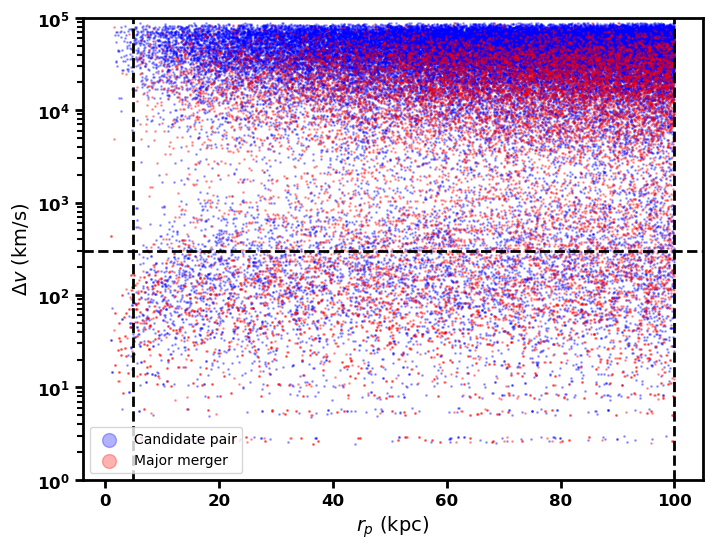

In [222]:
# Plot velocity separation against projected separation for all candidate pairs
fig, ax = plt.subplots(figsize = (8, 6))

major = mu >= MU_MIN

ax.scatter(rp[~major], dv[~major], s = 1, alpha = 0.3, color = 'blue', label = r'Candidate pair')
ax.scatter(rp[major], dv[major], s = 1, alpha = 0.3, color = 'red', label = r'Major merger')

# Pair selection cuts
ax.axvline(RP_MIN, color = 'black', linestyle = '--', linewidth = 2)
ax.axvline(RP_MAX, color = 'black', linestyle = '--', linewidth = 2)
ax.axhline(DV_MAX, color = 'black', linestyle = '--', linewidth = 2)

ax.set_yscale('log')
ax.set_ylim(1, 1e5)
ax.set_xlabel(r'$r_p$ (kpc)')
ax.set_ylabel(r'$\Delta v$ (km/s)')
ax.legend(markerscale = 10)

bold_ticks(ax)

plt.savefig("figs/velocity_separation.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/velocity_separation.png", format = "png", bbox_inches = "tight")

plt.show()

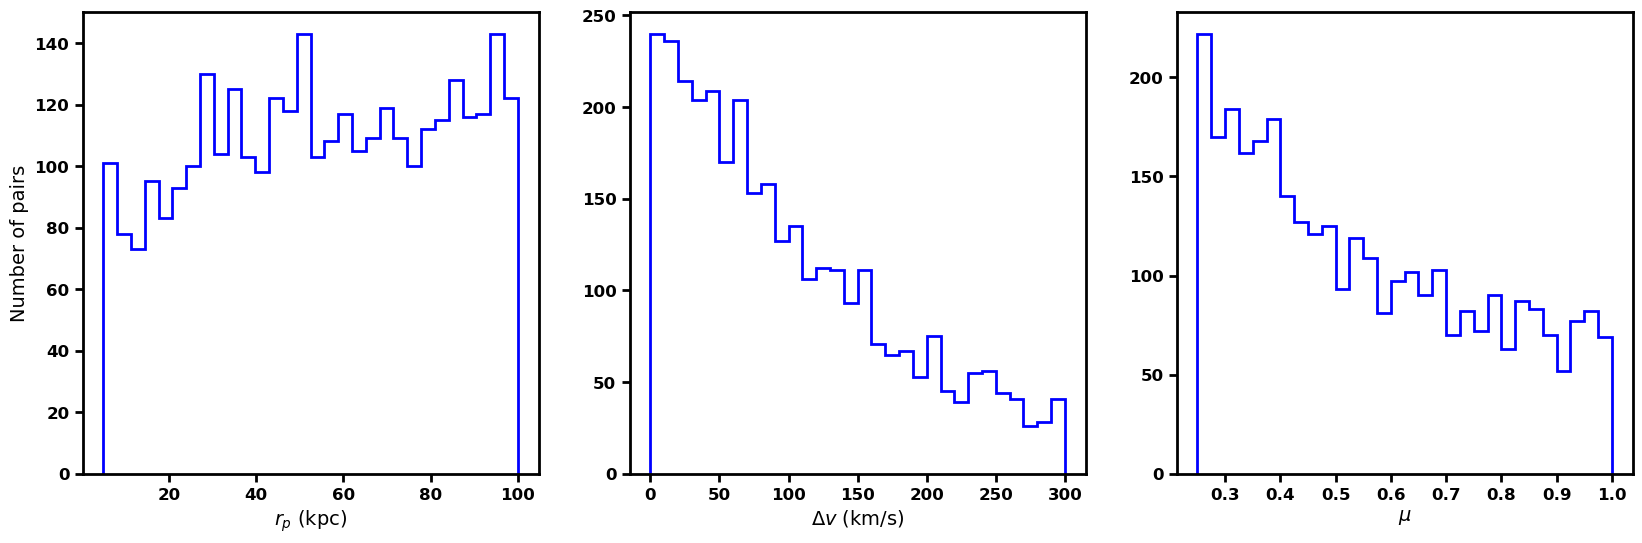

In [223]:
# Plot the distributions of the final pair properties
fig, axes = plt.subplots(1, 3, figsize = (20, 6))

axes[0].hist(pairs['rp'], bins = 30, range = (RP_MIN, RP_MAX), color = 'blue', histtype = 'step', linewidth = 2)
axes[0].set_xlabel(r'$r_p$ (kpc)')

axes[1].hist(pairs['dv'], bins = 30, range = (0, DV_MAX), color = 'blue', histtype = 'step', linewidth = 2)
axes[1].set_xlabel(r'$\Delta v$ (km/s)')

axes[2].hist(pairs['mu'], bins = 30, range = (MU_MIN, 1), color = 'blue', histtype = 'step', linewidth = 2)
axes[2].set_xlabel(r'$\mu$')

axes[0].set_ylabel('Number of pairs')

bold_ticks(*axes)

plt.savefig("figs/pair_properties.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/pair_properties.png", format = "png", bbox_inches = "tight")

plt.show()